
# Day 10 — Seq2Seq + Attention Demand Forecasting

Extends Day 9's Store 1 Rossmann sales forecasting.

- Historical window: 30 days
- Forecast horizon: 14 days
- Architecture: Encoder–Decoder LSTM with attention
- Evaluation: MAE and RMSE
- Baseline: Day 9 single-step LSTM


In [2]:

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

ROOT = Path.cwd().resolve()

if not (ROOT / "src").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.demand_forecasting import (
    LOOKBACK,
    HORIZON,
    load_store_sales,
    prepare_data,
    build_attention_model,
    build_day9_baseline,
    recursive_baseline,
    metrics_by_horizon,
    forecast_next_14_days
)

keras.utils.set_random_seed(42)

DATA_PATH = ROOT / 'data' / 'rossmann' / 'train.csv'
MODEL_PATH = ROOT / 'models' / 'demand_seq2seq_attention.keras'
BASELINE_PATH = ROOT / 'models' / 'demand_lstm.keras'
SCALE_PATH = ROOT / 'models' / 'demand_day10_scale.json'

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)



## 1. Prepare multi-step forecasting data

Convert the daily sales data into:

- Encoder input: Previous 30 days
- Decoder target: Next 14 days

Use a chronological 80/20 split and scale using only the training period.


In [5]:

sales = load_store_sales(DATA_PATH, store=1)

(X_train, y_train), (X_test, y_test), test_starts, max_sales, split = prepare_data(sales)

print('Train:', X_train.shape, y_train.shape)
print('Test:', X_test.shape, y_test.shape)
print('Training cutoff:', sales.index[split])
print('Training max sales:', max_sales)


Train: (710, 30, 1) (710, 14, 1)
Test: (176, 30, 1) (176, 14, 1)
Training cutoff: 2015-01-24 00:00:00
Training max sales: 9528.0



## 2. Build and train Seq2Seq with Attention

The encoder reads 30 days of sales history.

The decoder generates 14 future sales predictions.

Additive attention allows each decoder step to focus on different encoder time steps.

Actual future sales are not provided to the decoder.


In [6]:

model, attention_model = build_attention_model()

model.summary()

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    shuffle=False,
    validation_split=0.1,
    verbose=1
)

model.save(MODEL_PATH)

import json

SCALE_PATH.write_text(
    json.dumps({
        'store': 1,
        'lookback': LOOKBACK,
        'horizon': HORIZON,
        'train_max_sales': max_sales,
        'train_split_index': split
    }, indent=2)
)

print('Saved:', MODEL_PATH)


Model: "demand_seq2seq_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history             │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder (LSTM)      │ [(None, 30, 32),  │      4,352 │ history[0][0]     │
│                     │ (None, 32),       │            │                   │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 14, 32)    │          0 │ encoder[0][1]     │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder (LSTM)      │ (None, 14, 32)    │      8,320 │ repeat_context[0… │
│                     │                   │            │ encoder[0][1],    │
│                     │                   │            │ encoder[0][2]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attention  │ [(None, 14, 32),  │         32 │ decoder[0][0],    │
│ (AdditiveAttention) │ (None, 14, 30)]   │            │ encoder[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combine             │ (None, 14, 64)    │          0 │ decoder[0][0],    │
│ (Concatenate)       │                   │            │ temporal_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sales               │ (None, 14, 1)     │         65 │ combine[0][0]     │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,769 (49.88 KB)

 Trainable params: 12,769 (49.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 0.0814 - mae: 0.2330 - val_loss: 0.0789 - val_mae: 0.2120
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0447 - mae: 0.1616 - val_loss: 0.0755 - val_mae: 0.2238
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0434 - mae: 0.1526 - val_loss: 0.0752 - val_mae: 0.2229
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0432 - mae: 0.1546 - val_loss: 0.0744 - val_mae: 0.2188
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0431 - mae: 0.1534 - val_loss: 0.0746 - val_mae: 0.2201
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0430 - mae: 0.1531 - val_loss: 0.0747 - val_mae: 0.2211
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0430 - mae: 0.1531 - val_loss: 0.0748 - val_mae: 0.2216
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0430 - mae: 0.1530 - val_loss: 0.0749 - val_mae: 0.2221
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.043


## 3. Compare against the Day 9 LSTM

The Day 9 LSTM predicts one day ahead.

To compare fairly, recursively generate 14-day predictions using the baseline.

Evaluate both models on identical test windows using:

- MAE
- RMSE

Report results for 7-day and 14-day horizons.


In [8]:

if BASELINE_PATH.exists():
    baseline = keras.models.load_model(BASELINE_PATH)
    print('Loaded Day 9 baseline:', BASELINE_PATH)

else:
    baseline = build_day9_baseline()

    scaled = (sales / max_sales).to_numpy(dtype='float32')

    bx, by = [], []

    for i in range(LOOKBACK, split):
        seq = scaled[i - LOOKBACK:i + 1]

        if np.isfinite(seq).all():
            bx.append(seq[:-1, None])
            by.append(seq[-1])

    baseline.fit(
        np.asarray(bx),
        np.asarray(by),
        epochs=20,
        batch_size=32,
        shuffle=False,
        verbose=1
    )

    baseline.save(BASELINE_PATH)

    print('Trained and saved Day 9-equivalent baseline:', BASELINE_PATH)


seq_pred = model.predict(X_test, verbose=0)

base_pred = recursive_baseline(
    baseline,
    X_test
)

comparison = pd.concat([
    metrics_by_horizon(
        y_test,
        seq_pred,
        max_sales
    ).assign(Model='Seq2Seq + Attention'),

    metrics_by_horizon(
        y_test,
        base_pred,
        max_sales
    ).assign(Model='Day 9 LSTM (recursive)')
], ignore_index=True)

print(
    comparison[
        ['Model', 'horizon_days', 'MAE', 'RMSE']
    ].round(2).to_string(index=False)
)


Loaded Day 9 baseline: C:\Users\Abhishek\Desktop\RetailMind-AI\models\demand_lstm.keras
                 Model  horizon_days     MAE    RMSE
   Seq2Seq + Attention             7 1430.53 1885.65
   Seq2Seq + Attention            14 1420.16 1877.68
Day 9 LSTM (recursive)             7 1362.34 1889.26
Day 9 LSTM (recursive)            14 1342.27 1884.56



## 4. Visualize forecasts and attention

Plot the actual sales against both model predictions.

Then visualize attention weights as a heatmap:

- X-axis: Historical days 1–30
- Y-axis: Forecast days 1–14

Attention weights indicate learned focus, not causal influence.


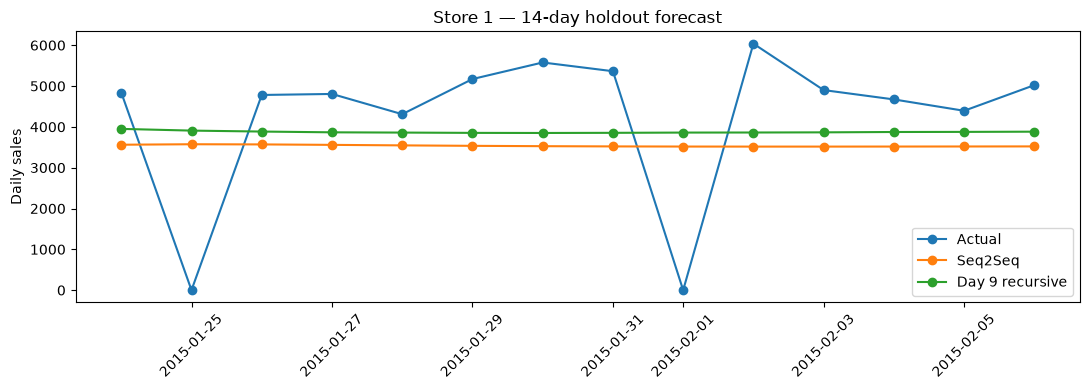

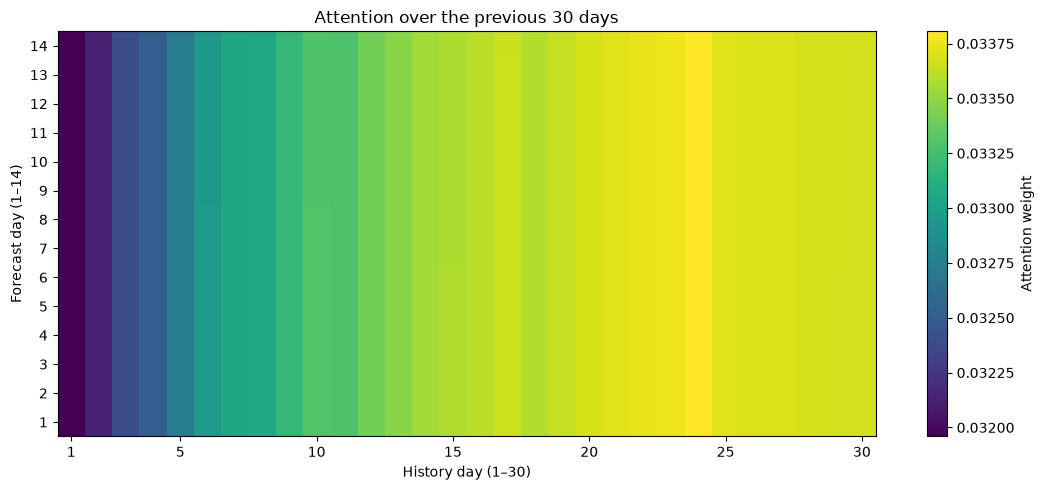

In [9]:

import matplotlib.pyplot as plt

sample = 0

forecast_dates = sales.index[
    test_starts[sample]:test_starts[sample] + HORIZON
]

plt.figure(figsize=(11, 4))

plt.plot(
    forecast_dates,
    y_test[sample, :, 0] * max_sales,
    marker='o',
    label='Actual'
)

plt.plot(
    forecast_dates,
    seq_pred[sample, :, 0] * max_sales,
    marker='o',
    label='Seq2Seq'
)

plt.plot(
    forecast_dates,
    base_pred[sample, :, 0] * max_sales,
    marker='o',
    label='Day 9 recursive'
)

plt.title('Store 1 — 14-day holdout forecast')
plt.ylabel('Daily sales')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


weights = attention_model.predict(
    X_test[sample:sample + 1],
    verbose=0
)[0]

plt.figure(figsize=(11, 5))

plt.imshow(
    weights,
    aspect='auto',
    origin='lower',
    cmap='viridis'
)

plt.colorbar(label='Attention weight')

plt.xlabel('History day (1–30)')
plt.ylabel('Forecast day (1–14)')

plt.xticks(
    [0, 4, 9, 14, 19, 24, 29],
    [1, 5, 10, 15, 20, 25, 30]
)

plt.yticks(range(14), range(1, 15))

plt.title('Attention over the previous 30 days')
plt.tight_layout()
plt.show()



## 5. Generate a 14-day procurement forecast

Use the latest 30 days of available sales history to forecast the next 14 days.

These are sales estimates, not purchase-order quantities.

Inventory levels, lead times, and safety stock would be needed to calculate actual procurement quantities.


In [10]:

future_forecast = forecast_next_14_days(
    model,
    sales,
    max_sales
)

print(future_forecast.round(0).to_string())

print(
    'Forecast total sales (14 days):',
    round(future_forecast['Predicted Sales'].sum())
)


            Predicted Sales
Date                       
2015-08-01           3660.0
2015-08-02           3695.0
2015-08-03           3715.0
2015-08-04           3727.0
2015-08-05           3736.0
2015-08-06           3742.0
2015-08-07           3749.0
2015-08-08           3756.0
2015-08-09           3763.0
2015-08-10           3770.0
2015-08-11           3776.0
2015-08-12           3783.0
2015-08-13           3788.0
2015-08-14           3794.0
Forecast total sales (14 days): 52454
